# Module 4 · Causal Discovery with causal-learn
**⏱ 25 minutes** · 2:20 – 2:45

So far we *assumed* the causal graph. What if we don't know it? **Causal discovery** tries to learn (parts of) the graph from data — under strong assumptions.

**Learning objectives**
1. Understand the three families: **constraint-based** (PC, FCI), **score-based** (GES), **functional / asymmetry-based** (LiNGAM).
2. Know what each can and can't identify (Markov equivalence classes, hidden confounders, non-Gaussianity).
3. Inject **domain knowledge** (temporal tiers, forbidden edges) — the single most effective way to improve discovery.
4. Hand a discovered graph to **DoWhy** for effect estimation.

**Scenario C:** A transaction-monitoring system. Eight features with a *known* true graph:

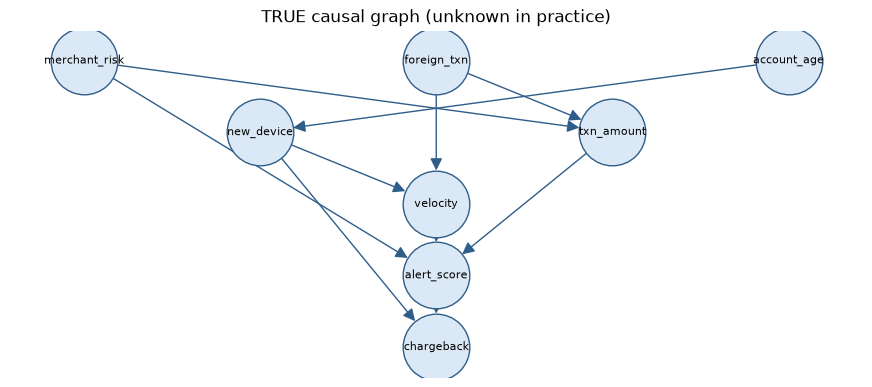

,mean,std
account_age,-0.017266,0.991698
merchant_risk,-0.014445,1.000739
txn_amount,-0.017978,1.196502
foreign_txn,-0.007380,0.996436
new_device,0.007829,0.988387
velocity,-0.000362,1.238671
alert_score,-0.034663,1.819135
chargeback,-0.024931,2.048757


In [1]:
import sys, pathlib, warnings, io, contextlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from causal_utils import (make_discovery_data, DISCOVERY_NODES, DISCOVERY_EDGES,
                          true_adjacency, compare_graphs, plot_dag)

df = make_discovery_data(n=5_000, seed=1)
A_TRUE = true_adjacency()
NODES = DISCOVERY_NODES
fig, ax = plt.subplots(figsize=(11, 4.5))
plot_dag(DISCOVERY_EDGES, nodes=NODES, ax=ax, title="TRUE causal graph (unknown in practice)")
plt.show()
df.describe().T[["mean", "std"]]

## 4.1 Key assumptions & the Markov equivalence class
- **Causal Markov:** each variable is independent of its non-descendants given its parents.
- **Faithfulness:** *all* independencies in the data come from the graph (no exact cancellations).
- **Causal sufficiency:** no hidden common causes (PC, GES) — relaxed by **FCI**.

From observational data and independence tests alone, we can only learn the graph up to its **Markov equivalence class** (a CPDAG): edges that participate in a **v-structure** ($A \rightarrow C \leftarrow B$) can be oriented; others may remain undirected.

> `A → B → C`, `A ← B ← C` and `A ← B → C` imply the *same* independencies — data alone can't tell them apart.

### Helper: convert causal-learn graphs to adjacency matrices
causal-learn encodes edges in `G.graph`: `graph[j, i] == 1 and graph[i, j] == -1` means **i → j**; `-1/-1` means undirected **i — j**; `1/1` means bidirected **i ↔ j**.

In [2]:
def cl_to_adj(G):
    g, n = G.graph, G.graph.shape[0]
    M = np.zeros((n, n), int)
    for i in range(n):
        for j in range(n):
            if g[j, i] == 1 and g[i, j] == -1:        # i -> j
                M[i, j] = 1
            elif g[i, j] == g[j, i] and g[i, j] != 0:   # undirected or bidirected
                M[i, j] = M[j, i] = 1
    return M

def adj_to_edges(M, names=NODES):
    directed, undirected = [], []
    for i in range(len(names)):
        for j in range(len(names)):
            if M[i, j] and not M[j, i]:
                directed.append((names[i], names[j]))
            elif M[i, j] and M[j, i] and i < j:
                undirected.append((names[i], names[j]))
    return directed, undirected

def show(M, title):
    d, u = adj_to_edges(M)
    fig, ax = plt.subplots(figsize=(11, 4.2))
    pos = None
    import networkx as nx
    G = nx.DiGraph(DISCOVERY_EDGES);
    for layer, ns in enumerate(nx.topological_generations(G)):
        for nd in ns: G.nodes[nd]["layer"] = layer
    pos = {k: (v[0], -v[1]) for k, v in nx.multipartite_layout(G, subset_key="layer", align="horizontal").items()}
    plot_dag(d, nodes=NODES, ax=ax, title=title + "   (red dashed = undirected)", undirected=u, pos=pos)
    plt.show()

## 4.2 PC algorithm (constraint-based)
1. Start from a complete undirected graph.
2. Remove edge $X - Y$ if some conditioning set $S$ makes $X \perp Y \mid S$ (here: Fisher-z partial-correlation test).
3. Orient v-structures, then propagate orientations (Meek rules).

Graph Nodes:
account_age;merchant_risk;txn_amount;foreign_txn;new_device;velocity;alert_score;chargeback

Graph Edges:
1. account_age --- new_device
2. merchant_risk --> txn_amount
3. merchant_risk --> alert_score
4. foreign_txn --> txn_amount
5. txn_amount --> alert_score
6. foreign_txn --> velocity
7. new_device --> velocity
8. new_device --> chargeback
9. velocity --> alert_score
10. alert_score --> chargeback



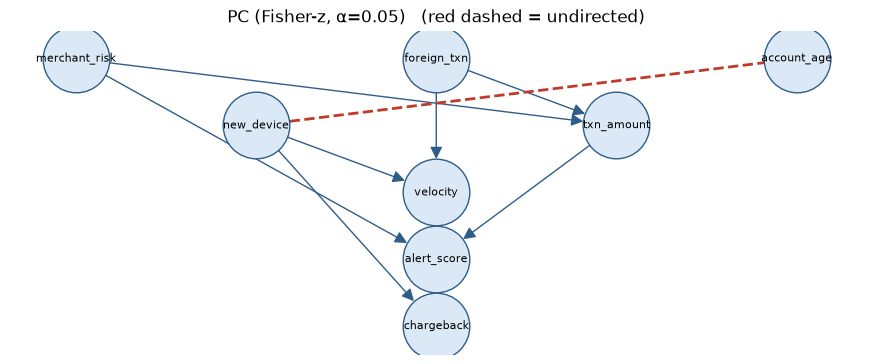

skeleton_precision     1.0
skeleton_recall        1.0
skeleton_f1            1.0
correctly_oriented     9.0
left_undirected        1.0
reversed               0.0
true_edges            10.0
SHD                    1.0
dtype: float64

In [3]:
from causallearn.search.ConstraintBased.PC import pc
from causallearn.utils.cit import fisherz

cg = pc(df.values, alpha=0.05, indep_test=fisherz, node_names=NODES, show_progress=False)
A_pc = cl_to_adj(cg.G)
print(cg.G)
show(A_pc, "PC (Fisher-z, α=0.05)")
compare_graphs(A_TRUE, A_pc)

PC recovers the skeleton and most orientations. `account_age — new_device` stays **undirected**: no v-structure points into `new_device`, so the data can't distinguish `account_age → new_device` from `new_device → account_age`. That's not a bug — it's the **limit of what's identifiable**.

## 4.3 GES (score-based)
Greedy Equivalence Search moves through equivalence classes, adding then removing edges to maximize a score (BIC). Often more robust than PC to individual test errors.

In [4]:
from causallearn.search.ScoreBased.GES import ges
rec = ges(df.values, score_func="local_score_BIC", node_names=NODES)
A_ges = cl_to_adj(rec["G"])
compare_graphs(A_TRUE, A_ges)

skeleton_precision     1.0
skeleton_recall        1.0
skeleton_f1            1.0
correctly_oriented     9.0
left_undirected        1.0
reversed               0.0
true_edges            10.0
SHD                    1.0
dtype: float64

## 4.4 Adding domain knowledge: temporal tiers
We know the *process order*: account/merchant attributes exist **before** a transaction; transaction features exist **before** the alert score; chargebacks happen **last**. Causes can't flow backwards in time — so we forbid those edges.

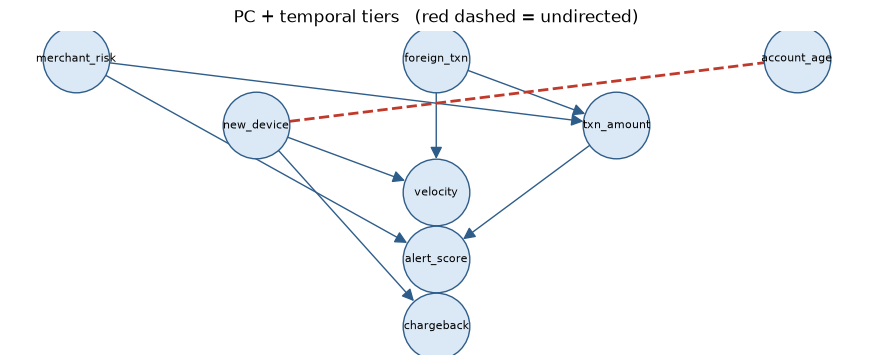

skeleton_precision     1.0
skeleton_recall        1.0
skeleton_f1            1.0
correctly_oriented     9.0
left_undirected        1.0
reversed               0.0
true_edges            10.0
SHD                    1.0
dtype: float64

In [5]:
from causallearn.utils.PCUtils.BackgroundKnowledge import BackgroundKnowledge

TIERS = {"account_age": 0, "merchant_risk": 0, "foreign_txn": 0, "new_device": 0,
         "txn_amount": 1, "velocity": 1, "alert_score": 2, "chargeback": 3}
bk = BackgroundKnowledge()
for node in cg.G.get_nodes():                          # GraphNode objects from the earlier run
    bk.add_node_to_tier(node, TIERS[node.get_name()])

cg_bk = pc(df.values, alpha=0.05, indep_test=fisherz, node_names=NODES,
           background_knowledge=bk, show_progress=False)
A_pc_bk = cl_to_adj(cg_bk.G)
show(A_pc_bk, "PC + temporal tiers")
compare_graphs(A_TRUE, A_pc_bk)

Wait — `account_age` and `new_device` are in the *same* tier, so the tiers can't orient that edge. One more piece of knowledge does it: *a device can't change how old the account is.*

In [6]:
from causallearn.graph.GraphNode import GraphNode
bk.add_forbidden_by_node(GraphNode("new_device"), GraphNode("account_age"))
cg_bk2 = pc(df.values, alpha=0.05, indep_test=fisherz, node_names=NODES,
            background_knowledge=bk, show_progress=False)
A_pc_bk2 = cl_to_adj(cg_bk2.G)
compare_graphs(A_TRUE, A_pc_bk2)

skeleton_precision     1.0
skeleton_recall        1.0
skeleton_f1            1.0
correctly_oriented    10.0
left_undirected        0.0
reversed               0.0
true_edges            10.0
SHD                    0.0
dtype: float64

## 4.5 LiNGAM: breaking the equivalence class with non-Gaussianity
If relationships are **linear** and noise is **non-Gaussian**, the full DAG is identifiable (ICA-based asymmetry: regressing the effect on the cause leaves residuals *independent* of the cause, but not the other way around). Many financial variables (amounts, counts, durations) are strongly non-Gaussian.

In [7]:
from causallearn.search.FCMBased import lingam
df_ng = make_discovery_data(n=5_000, seed=1, noise="uniform")   # same graph, non-Gaussian noise

lg = lingam.DirectLiNGAM(random_state=0)
lg.fit(df_ng.values)
B = lg.adjacency_matrix_                   # B[i, j] = effect of j on i
A_lingam = (np.abs(B.T) > 0.1).astype(int) # convert to A[i, j] = i -> j
print("Causal order:", [NODES[i] for i in lg.causal_order_])
pd.DataFrame(B.T, index=NODES, columns=NODES).round(2).replace(0, "")

Causal order: ['foreign_txn', 'account_age', 'merchant_risk', 'new_device', 'velocity', 'txn_amount', 'alert_score', 'chargeback']


,account_age,merchant_risk,txn_amount,foreign_txn,new_device,velocity,alert_score,chargeback
account_age,,,,,-0.72,,,
merchant_risk,,,0.81,,,,0.51,
txn_amount,,,,,,,0.71,
foreign_txn,,,0.7,,,0.6,,
new_device,,,,,,0.9,,0.59
velocity,,,,,,,0.8,
alert_score,,,,,,,,0.9
chargeback,,,,,,,,


In [8]:
compare_graphs(A_TRUE, A_lingam)

skeleton_precision     1.0
skeleton_recall        1.0
skeleton_f1            1.0
correctly_oriented    10.0
left_undirected        0.0
reversed               0.0
true_edges            10.0
SHD                    0.0
dtype: float64

LiNGAM orients **every** edge — including `account_age → new_device` — and estimates the coefficients (compare: true `account_age → new_device` = −0.7, `alert_score → chargeback` = 0.9).

## 4.6 FCI: what if there are hidden confounders?
Suppose we **didn't record** `foreign_txn`, which drives both `txn_amount` and `velocity`. PC/GES would wrongly draw a direct edge between them. **FCI** outputs a PAG with richer marks:

| Mark | Meaning |
|---|---|
| `A --> B` | A causes B (no hidden confounding needed) |
| `A <-> B` | **hidden common cause** of A and B |
| `A o-> B` | B is not an ancestor of A; A may cause B or share a latent cause |
| `A o-o B` | undetermined |

In [9]:
from causallearn.search.ConstraintBased.FCI import fci
df_hidden = df.drop(columns=["foreign_txn"])
with contextlib.redirect_stdout(io.StringIO()):          # silence verbose logging
    pag, _ = fci(df_hidden.values, fisherz, 0.05, node_names=list(df_hidden.columns), show_progress=False)
print(pag)

Graph Nodes:
account_age;merchant_risk;txn_amount;new_device;velocity;alert_score;chargeback

Graph Edges:
1. account_age o-o new_device
2. merchant_risk o-> txn_amount
3. merchant_risk o-> alert_score
4. txn_amount <-> velocity
5. txn_amount --> alert_score
6. new_device o-> velocity
7. new_device --> chargeback
8. velocity --> alert_score
9. alert_score --> chargeback



🎯 FCI flags **`txn_amount <-> velocity`**: the signature of an unmeasured common cause — exactly the `foreign_txn` we hid. In practice this is a prompt to *go find that data*, or to avoid adjustment strategies that assume it isn't there.

## 4.7 From discovered graph to causal effect (causal-learn → DoWhy)
**Question:** how much would chargebacks fall if we could reduce transaction **velocity** by one unit (e.g., via velocity limits)? True total effect = 0.8 × 0.9 = **0.72**.
Note `new_device` confounds velocity and chargeback.

In [10]:
import logging; logging.getLogger("dowhy").setLevel(logging.ERROR)
from dowhy import CausalModel
import statsmodels.formula.api as smf

directed, _ = adj_to_edges(A_pc_bk2)          # discovered + domain knowledge
dot = "digraph {" + " ".join(f"{a} -> {b};" for a, b in directed) + "}"
dm = CausalModel(data=df, treatment="velocity", outcome="chargeback", graph=dot)
ident = dm.identify_effect(proceed_when_unidentifiable=True)
est = dm.estimate_effect(ident, method_name="backdoor.linear_regression")
naive = smf.ols("chargeback ~ velocity", data=df).fit().params["velocity"]
print("Backdoor adjustment set:", ident.get_backdoor_variables())
print(f"Naive regression slope   : {naive:.3f}")
print(f"DoWhy on discovered graph: {est.value:.3f}")
print("True total effect        : 0.720")

Backdoor adjustment set: ['new_device', 'foreign_txn']
Naive regression slope   : 1.238
DoWhy on discovered graph: 0.718
True total effect        : 0.720


---
## ✋ Exercise 4.1 (5 min) — how fragile is discovery?
1. Re-run PC on `make_discovery_data(n=5_000, seed=s)` for `s` in `[2, 11, 15]` and on a **small sample** `n=500`. Record SHD with `compare_graphs`.
2. Re-run with **GES** on the same data. Which is more stable?
3. What does this tell you about using a discovered graph *without* expert review?

In [11]:
# YOUR CODE HERE

**✅ Solution (instructor copy)**

In [12]:
rows = []
for n, s in [(5000, 2), (5000, 11), (5000, 15), (500, 1), (500, 2)]:
    d = make_discovery_data(n=n, seed=s)
    shd_pc = compare_graphs(A_TRUE, cl_to_adj(pc(d.values, 0.05, fisherz, show_progress=False).G))["SHD"]
    shd_ges = compare_graphs(A_TRUE, cl_to_adj(ges(d.values)["G"]))["SHD"]
    rows.append(dict(n=n, seed=s, SHD_PC=shd_pc, SHD_GES=shd_ges))
pd.DataFrame(rows)
# A single wrong CI test early in PC can cascade into several mis-oriented edges.
# GES is usually more stable here. Discovery output is a HYPOTHESIS for experts to
# review -- never a substitute for domain knowledge.

,n,seed,SHD_PC,SHD_GES
0,5000,2,1.0,1.0
1,5000,11,2.0,1.0
2,5000,15,1.0,1.0
3,500,1,8.0,2.0
4,500,2,11.0,1.0


## 🔑 Key takeaways — Module 4
1. Discovery recovers graphs only **up to equivalence** (PC/GES) unless you add assumptions (LiNGAM: non-Gaussian, linear) or knowledge (tiers, forbidden edges).
2. **Domain knowledge is the highest-ROI input** — temporal ordering alone fixes many errors.
3. **FCI** relaxes "no hidden confounders" and can *flag* where they likely exist.
4. Results are sensitive to sample size, test choice and α. Treat a discovered graph as a **hypothesis generator** for experts, then validate it.
5. Discovered (and reviewed) graphs plug straight into **DoWhy** for identification and estimation.

➡️ Final module: `05_Capstone_and_Wrap-up.ipynb`